In [1]:
# Import the packages
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

In [2]:
# Select the device type according to your hardware
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [3]:
# Data transformation for pre-processing
transform = transforms.Compose([
    transforms.Pad(4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32),
    transforms.ToTensor()])

In [4]:
# Load your training data and testing data
train_dataset = torchvision.datasets.CIFAR10(root='data/',
                                             train=True,
                                             transform=transform,
                                             download=True)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128,
                                          shuffle=True, num_workers=0)

test_dataset = torchvision.datasets.CIFAR10(root='data/',
                                             train=False,
                                             transform=transforms.ToTensor(),
                                             download=True)

test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128,
                                          shuffle=False, num_workers=0)

100%|██████████| 170M/170M [00:06<00:00, 28.0MB/s]


In [5]:
# Data matrix info
image, label = train_dataset[0]
print(f"Shape of the image: {image.size()}")
print(f"Label of the image: {label}")

Shape of the image: torch.Size([3, 32, 32])
Label of the image: 6


Text(0.5, 1.0, '6')

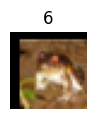

In [6]:
# Visualization
from matplotlib import pyplot as plt
image_np = image.numpy()
image_np = image_np.transpose(1, 2, 0)
plt.figure(figsize=(1, 1))
plt.imshow(image_np)
plt.axis("off")
plt.title(str(label))

In [7]:
# ResNet models
import torch.nn.init as init
from torch.autograd import Variable

__all__ = ['ResNet', 'resnet20', 'resnet32', 'resnet44', 'resnet56', 'resnet110', 'resnet1202']

def _weights_init(m):
    classname = m.__class__.__name__
    #print(classname)
    if isinstance(m, nn.Linear) or isinstance(m, nn.Conv2d):
        init.kaiming_normal_(m.weight)

class LambdaLayer(nn.Module):
    def __init__(self, lambd):
        super(LambdaLayer, self).__init__()
        self.lambd = lambd

    def forward(self, x):
        return self.lambd(x)


class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, option='A'):
        super(BasicBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            if option == 'A':
                """
                For CIFAR10 ResNet paper uses option A.
                """
                self.shortcut = LambdaLayer(lambda x:
                                            F.pad(x[:, :, ::2, ::2], (0, 0, 0, 0, planes//4, planes//4), "constant", 0))
            elif option == 'B':
                self.shortcut = nn.Sequential(
                     nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                     nn.BatchNorm2d(self.expansion * planes)
                )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out


class ResNet(nn.Module):
    def __init__(self, block, num_blocks, num_classes=10):
        super(ResNet, self).__init__()
        self.in_planes = 16

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        self.layer1 = self._make_layer(block, 16, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 32, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 64, num_blocks[2], stride=2)
        self.linear = nn.Linear(64, num_classes)

        self.apply(_weights_init)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1]*(num_blocks-1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_planes, planes, stride))
            self.in_planes = planes * block.expansion

        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = F.avg_pool2d(out, out.size()[3])
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out


def resnet20():
    return ResNet(BasicBlock, [3, 3, 3])

def resnet110():
    return ResNet(BasicBlock, [18, 18, 18])


In [10]:
# Define ResNet20 trained by yourself
model_mine = resnet20().to(device)

# Set training hyperparameters
epochs = 10
lr = 0.1
wd = 1e-4
momentum = 0.9

criterion = nn.CrossEntropyLoss().cuda()
optimizer = torch.optim.SGD(model_mine.parameters(), lr, momentum=momentum, weight_decay=wd)
lr_scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer,milestones=[100, 150])

In [21]:
# Train your own model
import time
from tqdm import tqdm
train_loss_list = []
train_accuracy_list = []
test_loss_list = []
test_accuracy_list = []

for epoch in (range(epochs)):
  print(f"epoch {epoch+1}: ", end=" ", flush=True)
  model_mine.train()
  train_num_data = 0
  train_loss_epoch = 0.
  train_correct_predictions = 0
  start_time = time.time()
  for images, labels in tqdm(train_loader):
    images, labels = images.to(device), labels.to(device)
    outputs = model_mine(images)
    loss = criterion(outputs, labels)

    # backward and update the model
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # calculate the training accuracy
    train_num_data += images.size(0)
    train_loss_epoch += loss.item() * images.size(0)
    predictions = outputs.argmax(dim=1)
    train_correct_predictions += torch.sum(predictions == labels)

  train_loss_epoch /= train_num_data
  train_accuracy = train_correct_predictions / train_num_data * 100

  # test the model performance on test data
  with torch.no_grad():
    model_mine.eval()
    test_num_data = 0
    test_loss_epoch = 0.
    test_correct_predictions = 0
    for images, labels in test_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model_mine(images)
      loss = criterion(outputs, labels)

      test_num_data += images.size(0)
      test_loss_epoch += loss.item() * images.size(0)
      predictions = outputs.argmax(dim=1)
      test_correct_predictions += torch.sum(predictions == labels)

  test_loss_epoch /= test_num_data
  test_accuracy = test_correct_predictions / test_num_data * 100

  end_time = time.time()

  print(f"Training time: {(end_time-start_time):.2f}s\t training loss: {train_loss_epoch:.2f}\t training accuracy: {train_accuracy:.2f}%\t testing loss: {test_loss_epoch:.2f}\t testing accuracy: {test_accuracy:.2f}%")
  train_loss_list.append(train_loss_epoch)
  train_accuracy_list.append(train_accuracy.item())
  test_loss_list.append(test_loss_epoch)
  test_accuracy_list.append(test_accuracy.item())
  if train_accuracy.item()>= max(train_accuracy_list):
    torch.save(model_mine.state_dict(),'data/best_resnet20.pth')

epoch 1:  

100%|██████████| 391/391 [00:26<00:00, 14.91it/s]


Training time: 28.15s	 training loss: 0.36	 training accuracy: 87.27%	 testing loss: 0.53	 testing accuracy: 82.48%
epoch 2:  

100%|██████████| 391/391 [00:25<00:00, 15.10it/s]


Training time: 27.51s	 training loss: 0.35	 training accuracy: 87.90%	 testing loss: 0.52	 testing accuracy: 83.43%
epoch 3:  

100%|██████████| 391/391 [00:25<00:00, 15.25it/s]


... (11 outputs left out)

100%|██████████| 391/391 [00:25<00:00, 15.14it/s]


Training time: 27.43s	 training loss: 0.32	 training accuracy: 88.80%	 testing loss: 0.46	 testing accuracy: 84.62%
epoch 10:  

100%|██████████| 391/391 [00:25<00:00, 15.17it/s]


Training time: 27.38s	 training loss: 0.31	 training accuracy: 88.96%	 testing loss: 0.44	 testing accuracy: 85.49%


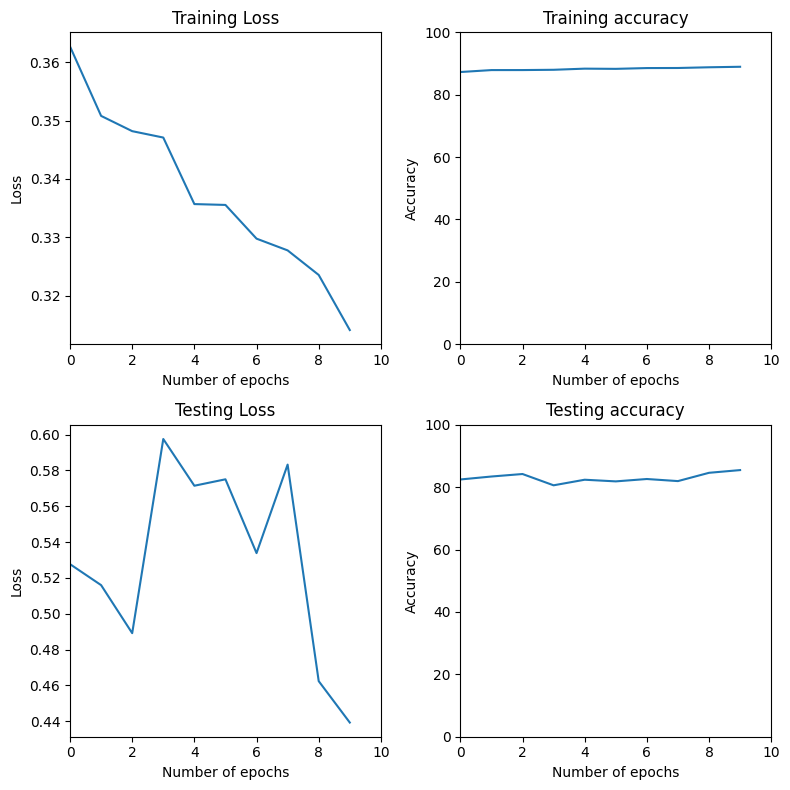

In [22]:
# Plot the training loss and accuracy curves
plt.figure(figsize=(8,8))
plt.subplot(221)
plt.plot(train_loss_list)
plt.title('Training Loss')
plt.xlabel('Number of epochs')
plt.ylabel('Loss')
plt.xlim(0, epochs)
plt.subplot(222)
plt.plot(train_accuracy_list)
plt.title('Training accuracy')
plt.xlabel('Number of epochs')
plt.ylabel('Accuracy')
plt.xlim(0, epochs)
plt.ylim(0, 100)
plt.subplot(223)
plt.plot(test_loss_list)
plt.title('Testing Loss')
plt.xlabel('Number of epochs')
plt.ylabel('Loss')
plt.xlim(0, epochs)
plt.subplot(224)
plt.plot(test_accuracy_list)
plt.title('Testing accuracy')
plt.xlabel('Number of epochs')
plt.ylabel('Accuracy')
plt.xlim(0, epochs)
plt.ylim(0, 100)
plt.tight_layout()

In [23]:
# Load pre-trained ResNet110
model_load = resnet110().to(device)
checkpoint = torch.load('data/pretrained_resnet110.pth')
model_load.load_state_dict(checkpoint)

# process the pretrained model (not the answer)
#checkpoint = torch.load('model.th')['state_dict']
#new_dict = {}
#for key, values in checkpoint.items():
#  new_key = key[7:]
#  new_dict[new_key] = values
#torch.save(new_dict, 'data/pretrained_resnet110.pth')

<All keys matched successfully>

In [24]:
# Test the loaded model
with torch.no_grad():
  model_load.eval()
  test_num_data = 0
  test_loss = 0.
  test_correct_predictions = 0
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model_load(images)
    loss = criterion(outputs, labels)

    test_num_data += images.size(0)
    test_loss += loss.item() * images.size(0)
    predictions = outputs.argmax(dim=1)
    test_correct_predictions += torch.sum(predictions == labels)

test_loss /= test_num_data
test_accuracy = test_correct_predictions / test_num_data * 100

print(f"testing loss: {test_loss:.2f}\t testing accuracy: {test_accuracy:.2f}%")


testing loss: 3.76	 testing accuracy: 46.91%


Analysis of your results.